In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [3]:
df = pd.read_csv(
    "../data/PRSA_Data_Aotizhongxin_20130301-20170228.csv"
)

df.head(10)

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin
5,6,2013,3,1,5,5.0,5.0,18.0,18.0,400.0,66.0,-2.2,1025.6,-19.6,0.0,N,3.7,Aotizhongxin
6,7,2013,3,1,6,3.0,3.0,18.0,32.0,500.0,50.0,-2.6,1026.5,-19.1,0.0,NNE,2.5,Aotizhongxin
7,8,2013,3,1,7,3.0,6.0,19.0,41.0,500.0,43.0,-1.6,1027.4,-19.1,0.0,NNW,3.8,Aotizhongxin
8,9,2013,3,1,8,3.0,6.0,16.0,43.0,500.0,45.0,0.1,1028.3,-19.2,0.0,NNW,4.1,Aotizhongxin
9,10,2013,3,1,9,3.0,8.0,12.0,28.0,400.0,59.0,1.2,1028.5,-19.3,0.0,N,2.6,Aotizhongxin


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       35064 non-null  int64  
 1   year     35064 non-null  int64  
 2   month    35064 non-null  int64  
 3   day      35064 non-null  int64  
 4   hour     35064 non-null  int64  
 5   PM2.5    34139 non-null  float64
 6   PM10     34346 non-null  float64
 7   SO2      34129 non-null  float64
 8   NO2      34041 non-null  float64
 9   CO       33288 non-null  float64
 10  O3       33345 non-null  float64
 11  TEMP     35044 non-null  float64
 12  PRES     35044 non-null  float64
 13  DEWP     35044 non-null  float64
 14  RAIN     35044 non-null  float64
 15  wd       34983 non-null  str    
 16  WSPM     35050 non-null  float64
 17  station  35064 non-null  str    
dtypes: float64(11), int64(5), str(2)
memory usage: 5.3 MB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
No,35064.0,17532.500000,10122.249256,1.0000,8766.75,17532.5,26298.25,35064.0
year,35064.0,2014.662560,1.177213,2013.0000,2014.00,2015.0,2016.00,2017.0
month,35064.0,6.522930,3.448752,1.0000,4.00,7.0,10.00,12.0
day,35064.0,15.729637,8.800218,1.0000,8.00,16.0,23.00,31.0
hour,35064.0,11.500000,6.922285,0.0000,5.75,11.5,17.25,23.0
PM2.5,34139.0,82.773611,82.135694,3.0000,22.00,58.0,114.00,898.0
PM10,34346.0,110.060391,95.223005,2.0000,38.00,87.0,155.00,984.0
SO2,34129.0,17.375901,22.823017,0.2856,3.00,9.0,21.00,341.0
NO2,34041.0,59.305833,37.116200,2.0000,30.00,53.0,82.00,290.0
CO,33288.0,1262.945145,1221.436236,100.0000,500.00,900.0,1500.00,10000.0


In [13]:
df["datetime"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]]
)

df = df.sort_values("datetime").reset_index(drop=True)

In [6]:
df.isnull().sum()

No            0
year          0
month         0
day           0
hour          0
PM2.5       925
PM10        718
SO2         935
NO2        1023
CO         1776
O3         1719
TEMP         20
PRES         20
DEWP         20
RAIN         20
wd           81
WSPM         14
station       0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

Soru : PM2.5 değişkeninin ortalaması 80, medyanı 50 çıkarsa bu bize dağılım hakkında ne söyleyebilir?

In [ ]:
df["PM2.5"].describe().T

"""
PM2.5 değişkeninin ortalaması 80, medyanı 50 ise dağılımın sağa çarpık olabileceğini düşünürüm.

Bunun nedeni, yüksek PM2.5 değerlerinin ortalamayı yukarı çekmesidir.

Bu durum veri setinde bazı dönemlerde oldukça yüksek hava kirliliği değerleri bulunabileceğini düşündürür.
"""

count    34139.000000
mean        82.773611
std         82.135694
min          3.000000
25%         22.000000
50%         58.000000
75%        114.000000
max        898.000000
Name: PM2.5, dtype: float64

In [19]:
missing_table = pd.DataFrame({
    "Eksik Sayısı": df.isna().sum(),
    "Eksik Oranı (%)": df.isna().mean() * 100
})

print(missing_table.round(2))

          Eksik Sayısı  Eksik Oranı (%)
No                   0             0.00
year                 0             0.00
month                0             0.00
day                  0             0.00
hour                 0             0.00
PM2.5              925             2.64
PM10               718             2.05
SO2                935             2.67
NO2               1023             2.92
CO                1776             5.07
O3                1719             4.90
TEMP                20             0.06
PRES                20             0.06
DEWP                20             0.06
RAIN                20             0.06
wd                  81             0.23
WSPM                14             0.04
station              0             0.00
datetime             0             0.00


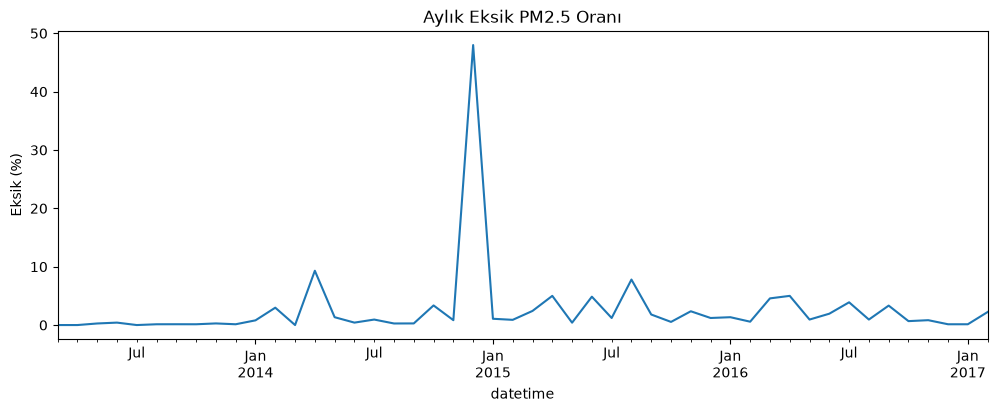

In [20]:
monthly_missing = (
    df.set_index("datetime")["PM2.5"]
    .isna()
    .resample("MS")
    .mean() * 100
)

monthly_missing.plot(figsize=(12, 4))
plt.title("Aylık Eksik PM2.5 Oranı")
plt.ylabel("Eksik (%)")
plt.show()

In [21]:
missing = df["PM2.5"].isna()

groups = (
    missing.ne(missing.shift()) |
    df["datetime"].diff().ne(pd.Timedelta(hours=1))
).cumsum()

missing_streaks = (
    df[missing]
    .groupby(groups[missing])
    .size()
)

print("Arka arkaya eksik dönem sayısı:",
      (missing_streaks > 1).sum())

Arka arkaya eksik dönem sayısı: 94


In [22]:
print("En uzun eksik ölçüm:",
      missing_streaks.max(), "saat")

En uzun eksik ölçüm: 343 saat


Soru : 
Bir zaman serisinde:
df["PM2.5"].interpolate()
kullanmak neden bazı tahmin senaryolarında veri sızıntısı oluşturabilir?

In [ ]:
#Cunku interpolate eksik degerleri doldururken gelecekteki olcumleri kullanabilir. Gelecekteki verilerle gecmisi doldurmak gercek zamanli tahminlerde veri sizintisina yol acabilir.

In [25]:
df["timestamp"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]]
)

df = df.sort_values("timestamp").reset_index(drop=True)

print("İlk tarih:", df["timestamp"].min())
print("Son tarih:", df["timestamp"].max())

İlk tarih: 2013-03-01 00:00:00
Son tarih: 2017-02-28 23:00:00


In [26]:
duplicates = df["timestamp"].duplicated().sum()

print("Tekrarlanan saat sayısı:", duplicates)

Tekrarlanan saat sayısı: 0


In [27]:
expected_hours = pd.date_range(
    start=df["timestamp"].min(),
    end=df["timestamp"].max(),
    freq="h"
)

missing_hours = expected_hours.difference(df["timestamp"])

print("Beklenen saat sayısı:", len(expected_hours))
print("Eksik saat sayısı:", len(missing_hours))

Beklenen saat sayısı: 35064
Eksik saat sayısı: 0


In [28]:
hourly_counts = (
    df.groupby("timestamp")
    .size()
    .reindex(expected_hours, fill_value=0)
)

print(hourly_counts.value_counts().sort_index())

1    35064
Name: count, dtype: int64


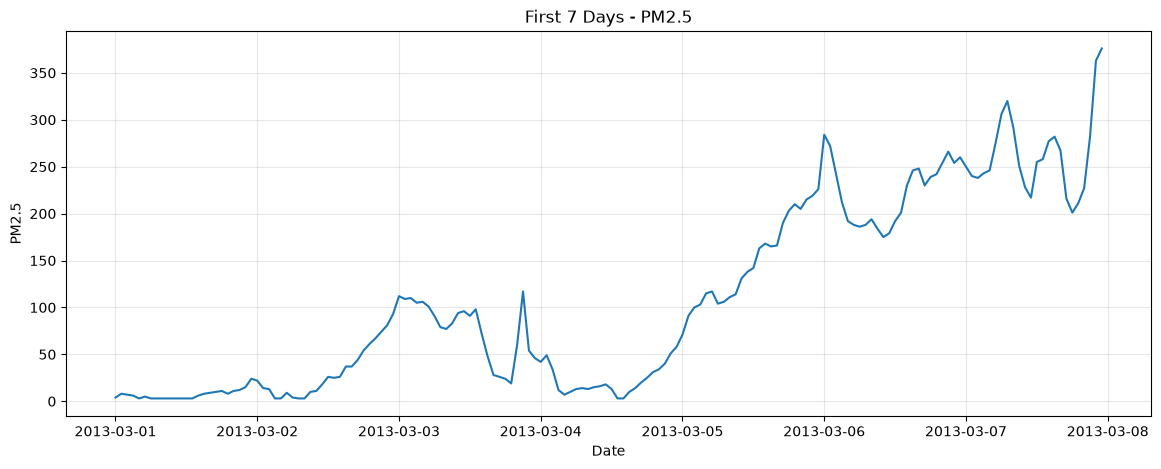

In [29]:
pm25_hourly = (
    df.groupby("timestamp")["PM2.5"]
    .mean()
    .reindex(expected_hours)
)

first_7_days = pm25_hourly.iloc[:168]

plt.figure(figsize=(14, 5))

plt.plot(
    first_7_days.index,
    first_7_days.values
)

plt.title("First 7 Days - PM2.5")
plt.xlabel("Date")
plt.ylabel("PM2.5")
plt.grid(alpha=0.3)
plt.show()

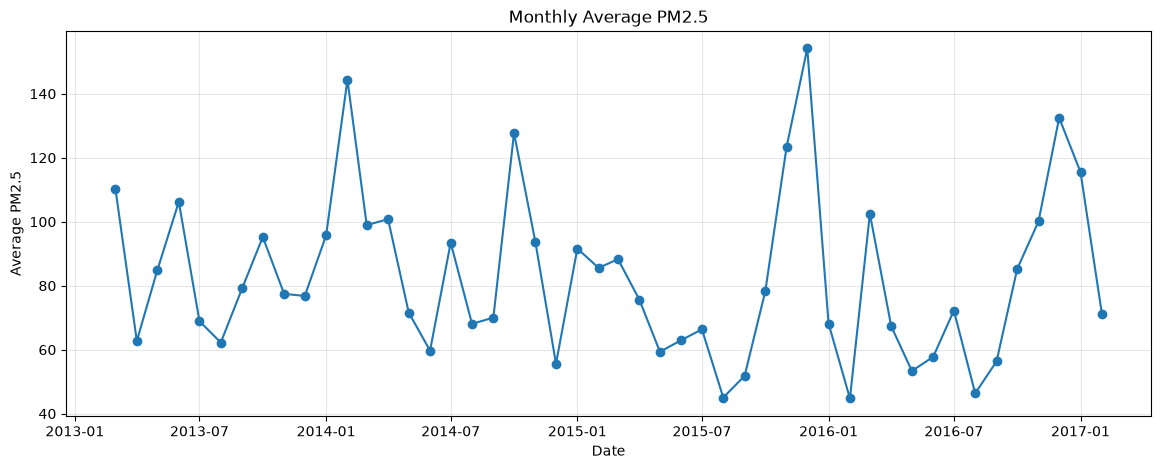

In [30]:
monthly_pm25 = pm25_hourly.resample("MS").mean()

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_pm25.index,
    monthly_pm25.values,
    marker="o"
)

plt.title("Monthly Average PM2.5")
plt.xlabel("Date")
plt.ylabel("Average PM2.5")
plt.grid(alpha=0.3)
plt.show()

In [31]:
df["target_pm25_next_hour"] = df["PM2.5"].shift(-1)

df[["timestamp", "PM2.5", "target_pm25_next_hour"]].head(10)

,timestamp,PM2.5,target_pm25_next_hour
0,2013-03-01 00:00:00,4.0,8.0
1,2013-03-01 01:00:00,8.0,7.0
2,2013-03-01 02:00:00,7.0,6.0
3,2013-03-01 03:00:00,6.0,3.0
4,2013-03-01 04:00:00,3.0,5.0
5,2013-03-01 05:00:00,5.0,3.0
6,2013-03-01 06:00:00,3.0,3.0
7,2013-03-01 07:00:00,3.0,3.0
8,2013-03-01 08:00:00,3.0,3.0
9,2013-03-01 09:00:00,3.0,3.0


In [33]:
next_timestamp = df["timestamp"].shift(-1)

valid_time = (
    next_timestamp - df["timestamp"]
    == pd.Timedelta(hours=1)
)

print("Geçerli zaman eşleşmeleri:", valid_time.sum())
print("Geçersiz zaman eşleşmeleri:", (~valid_time).sum())

df.loc[
    ~valid_time,
    "target_pm25_next_hour"
] = np.nan

Geçerli zaman eşleşmeleri: 35063
Geçersiz zaman eşleşmeleri: 1


In [34]:
valid_pairs = df[
    df["PM2.5"].notna()
    & df["target_pm25_next_hour"].notna()
].copy()

print("Geçerli tahmin çifti:", len(valid_pairs))

Geçerli tahmin çifti: 33929


In [35]:
valid_pairs[
    ["timestamp", "PM2.5", "target_pm25_next_hour"]
].head(10)

,timestamp,PM2.5,target_pm25_next_hour
0,2013-03-01 00:00:00,4.0,8.0
1,2013-03-01 01:00:00,8.0,7.0
2,2013-03-01 02:00:00,7.0,6.0
3,2013-03-01 03:00:00,6.0,3.0
4,2013-03-01 04:00:00,3.0,5.0
5,2013-03-01 05:00:00,5.0,3.0
6,2013-03-01 06:00:00,3.0,3.0
7,2013-03-01 07:00:00,3.0,3.0
8,2013-03-01 08:00:00,3.0,3.0
9,2013-03-01 09:00:00,3.0,3.0
